# Proyecto EDA · Campaña de telemarketing de un banco portugués

**Objetivo:** entender qué clientes contratan un depósito a plazo (`y`) tras la campaña de telemarketing, y de qué depende.

**Datos:**
- `bank-additional.csv`: una fila por contacto de la campaña, con datos del cliente, del contacto y del contexto económico.
- `customer-details.xlsx`: datos socioeconómicos de los clientes, en tres hojas según el año en que se dieron de alta (2012, 2013 y 2014).

**Índice**
1. Carga de datos
2. Exploración inicial
3. Limpieza y transformación
4. Unión de las dos fuentes
5. Análisis descriptivo
6. Visualización
7. Conclusiones

## 1. Carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RUTA_DATOS = "../data/raw/"

bank = pd.read_csv(RUTA_DATOS + "bank-additional.csv")

# sheet_name=None lee todas las hojas del Excel en un diccionario {nombre_hoja: DataFrame}
hojas_clientes = pd.read_excel(RUTA_DATOS + "customer-details.xlsx", sheet_name=None)

print("bank:", bank.shape)
for nombre, df in hojas_clientes.items():
    print(f"customer-details · hoja {nombre}: {df.shape}")

bank: (43000, 24)
customer-details · hoja 2012: (20115, 7)
customer-details · hoja 2013: (8965, 7)
customer-details · hoja 2014: (14090, 7)


In [2]:
# Unimos las tres hojas en un solo DataFrame y guardamos el año de alta de cada cliente
clientes = pd.concat(
    [df.assign(anio_alta=int(nombre)) for nombre, df in hojas_clientes.items()],
    ignore_index=True,
)
print("clientes:", clientes.shape)
clientes.head()

clientes: (43170, 8)


,Unnamed: 0,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,ID,anio_alta
0,0,161770,1,0,2012-04-04,29,089b39d8-e4d0-461b-87d4-814d71e0e079,2012
1,1,85477,1,1,2012-12-30,7,e9d37224-cb6f-4942-98d7-46672963d097,2012
2,2,147233,1,1,2012-02-02,5,3f9f49b5-e410-4948-bf6e-f9244f04918b,2012
3,3,121393,1,2,2012-12-21,29,9991fafb-4447-451a-8be2-b0df6098d13e,2012
4,4,63164,1,2,2012-06-20,20,eca60b76-70b6-4077-80ba-bc52e8ebb0eb,2012


## 2. Exploración inicial

In [3]:
bank.head()

,Unnamed: 0,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,latitude,longitude,id_
0,0,NaN,housemaid,MARRIED,basic.4y,0.0,0.0,0.0,telephone,261,1,999,0,NONEXISTENT,1.1,"93,994","-36,4","4,857",5191,no,2-agosto-2019,41.495,-71.233,089b39d8-e4d0-461b-87d4-814d71e0e079
1,1,57.0,services,MARRIED,high.school,NaN,0.0,0.0,telephone,149,1,999,0,NONEXISTENT,1.1,"93,994","-36,4",NaN,5191,no,14-septiembre-2016,34.601,-83.923,e9d37224-cb6f-4942-98d7-46672963d097
2,2,37.0,services,MARRIED,high.school,0.0,1.0,0.0,telephone,226,1,999,0,NONEXISTENT,1.1,"93,994","-36,4","4,857",5191,no,15-febrero-2019,34.939,-94.847,3f9f49b5-e410-4948-bf6e-f9244f04918b
3,3,40.0,admin.,MARRIED,basic.6y,0.0,0.0,0.0,telephone,151,1,999,0,NONEXISTENT,1.1,"93,994","-36,4",NaN,5191,no,29-noviembre-2015,49.041,-70.308,9991fafb-4447-451a-8be2-b0df6098d13e
4,4,56.0,services,MARRIED,high.school,0.0,0.0,1.0,telephone,307,1,999,0,NONEXISTENT,1.1,"93,994","-36,4",NaN,5191,no,29-enero-2017,38.033,-104.463,eca60b76-70b6-4077-80ba-bc52e8ebb0eb


In [4]:
bank.info()

<class 'pandas.DataFrame'>
RangeIndex: 43000 entries, 0 to 42999
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      43000 non-null  int64  
 1   age             37880 non-null  float64
 2   job             42655 non-null  str    
 3   marital         42915 non-null  str    
 4   education       41193 non-null  str    
 5   default         34019 non-null  float64
 6   housing         41974 non-null  float64
 7   loan            41974 non-null  float64
 8   contact         43000 non-null  str    
 9   duration        43000 non-null  int64  
 10  campaign        43000 non-null  int64  
 11  pdays           43000 non-null  int64  
 12  previous        43000 non-null  int64  
 13  poutcome        43000 non-null  str    
 14  emp.var.rate    43000 non-null  float64
 15  cons.price.idx  42529 non-null  str    
 16  cons.conf.idx   43000 non-null  str    
 17  euribor3m       33744 non-null  str    
 1

In [5]:
# Valores nulos por columna (número y %)
nulos = pd.DataFrame({
    "nulos": bank.isnull().sum(),
    "porcentaje": (bank.isnull().mean() * 100).round(2),
})
nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)

,nulos,porcentaje
euribor3m,9256,21.53
default,8981,20.89
age,5120,11.91
education,1807,4.20
loan,1026,2.39
housing,1026,2.39
cons.price.idx,471,1.10
job,345,0.80
date,248,0.58
marital,85,0.20


In [6]:
print("Filas duplicadas en bank:", bank.drop(columns="Unnamed: 0").duplicated().sum())
print("IDs duplicados en bank:", bank["id_"].duplicated().sum())
print("IDs duplicados en clientes:", clientes["ID"].duplicated().sum())
print("Nulos en clientes:", clientes.isnull().sum().sum())

Filas duplicadas en bank: 0
IDs duplicados en bank: 0
IDs duplicados en clientes: 0
Nulos en clientes: 0


In [7]:
# Valores únicos de las variables categóricas
categoricas = ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome", "y"]
for col in categoricas:
    print(f"{col}: {bank[col].unique().tolist()}")

job: ['housemaid', 'services', 'admin.', 'blue-collar', 'technician', 'retired', 'management', 'unemployed', 'self-employed', nan, 'entrepreneur', 'student']
marital: ['MARRIED', 'SINGLE', 'DIVORCED', nan]
education: ['basic.4y', 'high.school', 'basic.6y', 'basic.9y', 'professional.course', nan, 'university.degree', 'illiterate']
default: [0.0, nan, 1.0]
housing: [0.0, 1.0, nan]
loan: [0.0, 1.0, nan]
contact: ['telephone', 'cellular']
poutcome: ['NONEXISTENT', 'FAILURE', 'SUCCESS']
y: ['no', 'yes']


**Lo que hay que arreglar:**
- `Unnamed: 0` es un índice antiguo que no aporta información.
- `cons.price.idx`, `cons.conf.idx`, `euribor3m` y `nr.employed` son números, pero vienen como texto con **coma decimal**.
- `date` está en texto con el mes en español (por ejemplo, `2-agosto-2019`).
- Nulos en `age` (12 %), `euribor3m` (21 %), `default` (21 %), `education` (4 %), `housing` y `loan` (2 %) y, en menor medida, en otras columnas.
- `marital` y `poutcome` están en mayúsculas y el resto de categóricas en minúsculas.
- `default`, `housing` y `loan` están codificadas como 0/1 en decimal.
- No hay filas ni IDs duplicados.

## 3. Limpieza y transformación
### 3.1 Datos de la campaña (`bank`)

In [8]:
df = bank.drop(columns="Unnamed: 0").copy()

# Nombres de columna sin puntos, para poder escribirlos con más comodidad
df.columns = [col.replace(".", "_") for col in df.columns]

# Números que vienen como texto con coma decimal -> float
def texto_a_numero(serie):
    return pd.to_numeric(serie.astype(str).str.replace(",", ".", regex=False), errors="coerce")

columnas_coma = ["cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed"]
for col in columnas_coma:
    df[col] = texto_a_numero(df[col])

df[columnas_coma].dtypes

cons_price_idx    float64
cons_conf_idx     float64
euribor3m         float64
nr_employed       float64
dtype: object

In [9]:
# Fecha en español -> datetime
MESES = {
    "enero": 1, "febrero": 2, "marzo": 3, "abril": 4, "mayo": 5, "junio": 6,
    "julio": 7, "agosto": 8, "septiembre": 9, "octubre": 10, "noviembre": 11, "diciembre": 12,
}

def convertir_fecha(texto):
    if pd.isna(texto):
        return pd.NaT
    dia, mes, anio = texto.split("-")
    return pd.Timestamp(year=int(anio), month=MESES[mes.lower()], day=int(dia))

df["date"] = df["date"].apply(convertir_fecha)
df["contact_year"] = df["date"].dt.year.astype("Int64")
df["contact_month"] = df["date"].dt.month.astype("Int64")

print("Fechas sin dato:", df["date"].isna().sum())
df[["date", "contact_year", "contact_month"]].head()

Fechas sin dato: 248


,date,contact_year,contact_month
0,2019-08-02,2019,8
1,2016-09-14,2016,9
2,2019-02-15,2019,2
3,2015-11-29,2015,11
4,2017-01-29,2017,1


In [10]:
# Categóricas: todo en minúsculas y los nulos como "unknown"
for col in ["job", "marital", "education", "poutcome"]:
    df[col] = df[col].str.lower().fillna("unknown")

# default, housing y loan: 0/1 -> "no"/"yes"; los nulos pasan a "unknown"
for col in ["default", "housing", "loan"]:
    df[col] = df[col].map({0.0: "no", 1.0: "yes"}).fillna("unknown")

# Variable objetivo en formato numérico (1 = ha contratado)
df["y_num"] = (df["y"] == "yes").astype(int)

df[["job", "marital", "education", "default", "housing", "loan", "poutcome", "y", "y_num"]].head()

,job,marital,education,default,housing,loan,poutcome,y,y_num
0,housemaid,married,basic.4y,no,no,no,nonexistent,no,0
1,services,married,high.school,unknown,no,no,nonexistent,no,0
2,services,married,high.school,no,yes,no,nonexistent,no,0
3,admin.,married,basic.6y,no,no,no,nonexistent,no,0
4,services,married,high.school,no,no,yes,nonexistent,no,0


In [11]:
# Edad: 12 % de nulos. Imputamos con la mediana de su profesión (la edad depende mucho de ella:
# estudiantes y jubilados están en extremos opuestos) y marcamos qué valores son imputados.
df["age_imputada"] = df["age"].isna()
mediana_edad_por_trabajo = df.groupby("job")["age"].transform("median")
df["age"] = df["age"].fillna(mediana_edad_por_trabajo).round().astype(int)

# Indicadores macroeconómicos: son iguales para todos los contactos del mismo periodo.
# nr_employed y emp_var_rate no tienen nulos e identifican ese periodo, así que rellenamos
# euribor3m y cons_price_idx con la mediana de su grupo.
for col in ["euribor3m", "cons_price_idx"]:
    df[col] = df[col].fillna(df.groupby(["emp_var_rate", "nr_employed"])[col].transform("median"))

print(df[["age", "euribor3m", "cons_price_idx"]].isnull().sum())

age               0
euribor3m         0
cons_price_idx    0
dtype: int64


In [12]:
# Nuevas columnas para el análisis
df["grupo_edad"] = pd.cut(
    df["age"], bins=[0, 25, 35, 45, 55, 65, 120],
    labels=["<25", "25-34", "35-44", "45-54", "55-64", "65+"], right=False,
)
df["contactado_antes"] = np.where(df["pdays"] == 999, "no", "yes")   # 999 = nunca contactado
df["duracion_min"] = (df["duration"] / 60).round(2)
df["llamadas_campania"] = pd.cut(
    df["campaign"], bins=[0, 1, 2, 3, 5, 100], labels=["1", "2", "3", "4-5", "6+"],
)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 43000 entries, 0 to 42999
Data columns (total 31 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   age                43000 non-null  int64         
 1   job                43000 non-null  str           
 2   marital            43000 non-null  str           
 3   education          43000 non-null  str           
 4   default            43000 non-null  str           
 5   housing            43000 non-null  str           
 6   loan               43000 non-null  str           
 7   contact            43000 non-null  str           
 8   duration           43000 non-null  int64         
 9   campaign           43000 non-null  int64         
 10  pdays              43000 non-null  int64         
 11  previous           43000 non-null  int64         
 12  poutcome           43000 non-null  str           
 13  emp_var_rate       43000 non-null  float64       
 14  cons_price_idx   

### 3.2 Datos de los clientes (`clientes`)

In [13]:
clientes = (
    clientes.drop(columns="Unnamed: 0")
    .rename(columns={"ID": "id_"})
)
clientes["Dt_Customer"] = pd.to_datetime(clientes["Dt_Customer"])
clientes["hijos_total"] = clientes["Kidhome"] + clientes["Teenhome"]
clientes["tramo_ingresos"] = pd.qcut(clientes["Income"], q=4, labels=["Q1 (bajos)", "Q2", "Q3", "Q4 (altos)"])
clientes.describe()

,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,anio_alta,hijos_total
count,43170.000000,43170.000000,43170.000000,43170,43170.000000,43170.000000,43170.000000
mean,93227.389622,1.004749,0.998633,2013-05-11 22:09:47.407922,16.591290,2012.860435,2.003382
min,5841.000000,0.000000,0.000000,2012-01-01 00:00:00,1.000000,2012.000000,0.000000
25%,49608.000000,0.000000,0.000000,2012-07-16 00:00:00,9.000000,2012.000000,1.000000
50%,93009.500000,1.000000,1.000000,2013-03-01 00:00:00,17.000000,2013.000000,2.000000
75%,136740.500000,2.000000,2.000000,2014-03-28 00:00:00,25.000000,2014.000000,3.000000
max,180802.000000,2.000000,2.000000,2014-12-31 00:00:00,32.000000,2014.000000,4.000000
std,50498.181989,0.815996,0.816008,NaN,9.241769,0.879132,1.152982


## 4. Unión de las dos fuentes
Comprobamos primero que `id_` (campaña) y `ID` (clientes) son la misma clave.

In [14]:
ids_bank = set(df["id_"])
ids_clientes = set(clientes["id_"])
print("IDs de la campaña que están en clientes:", len(ids_bank & ids_clientes), "de", len(ids_bank))
print("Clientes sin contacto en la campaña:", len(ids_clientes - ids_bank))

IDs de la campaña que están en clientes: 43000 de 43000
Clientes sin contacto en la campaña: 170


In [15]:
# Todos los contactos tienen su cliente, así que un inner join no pierde filas de la campaña.
# validate="one_to_one" comprueba que no hay claves repetidas en ninguno de los dos lados.
datos = df.merge(clientes, on="id_", how="inner", validate="one_to_one")
print("Dataset final:", datos.shape)
datos.head()

Dataset final: (43000, 39)


,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y,date,latitude,longitude,id_,contact_year,contact_month,y_num,age_imputada,grupo_edad,contactado_antes,duracion_min,llamadas_campania,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,anio_alta,hijos_total,tramo_ingresos
0,45,housemaid,married,basic.4y,no,no,no,telephone,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2019-08-02,41.495,-71.233,089b39d8-e4d0-461b-87d4-814d71e0e079,2019,8,0,True,45-54,no,4.35,1,161770,1,0,2012-04-04,29,2012,1,Q4 (altos)
1,57,services,married,high.school,unknown,no,no,telephone,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2016-09-14,34.601,-83.923,e9d37224-cb6f-4942-98d7-46672963d097,2016,9,0,False,55-64,no,2.48,1,85477,1,1,2012-12-30,7,2012,2,Q2
2,37,services,married,high.school,no,yes,no,telephone,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2019-02-15,34.939,-94.847,3f9f49b5-e410-4948-bf6e-f9244f04918b,2019,2,0,False,35-44,no,3.77,1,147233,1,1,2012-02-02,5,2012,2,Q4 (altos)
3,40,admin.,married,basic.6y,no,no,no,telephone,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2015-11-29,49.041,-70.308,9991fafb-4447-451a-8be2-b0df6098d13e,2015,11,0,False,35-44,no,2.52,1,121393,1,2,2012-12-21,29,2012,3,Q3
4,56,services,married,high.school,no,no,yes,telephone,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2017-01-29,38.033,-104.463,eca60b76-70b6-4077-80ba-bc52e8ebb0eb,2017,1,0,False,55-64,no,5.12,1,63164,1,2,2012-06-20,20,2012,3,Q2


In [16]:
# Guardamos el dataset limpio y unido
datos.to_csv("../data/processed/bank_clientes_limpio.csv", index=False)

## 5. Análisis descriptivo
### 5.1 Variables numéricas

In [17]:
numericas = ["age", "duration", "campaign", "previous", "Income", "NumWebVisitsMonth",
             "hijos_total", "euribor3m", "emp_var_rate", "cons_conf_idx"]
resumen = datos[numericas].agg(["mean", "median", "std", "min", "max"]).T.round(2)
resumen

,mean,median,std,min,max
age,39.82,38.00,9.96,17.00,98.00
duration,257.74,179.00,258.67,0.00,4918.00
campaign,2.57,2.00,2.77,1.00,56.00
previous,0.17,0.00,0.50,0.00,7.00
Income,93241.20,93050.50,50498.32,5841.00,180802.00
NumWebVisitsMonth,16.59,17.00,9.24,1.00,32.00
hijos_total,2.00,2.00,1.15,0.00,4.00
euribor3m,3.61,4.86,1.74,0.63,5.04
emp_var_rate,0.08,1.10,1.57,-3.40,1.40
cons_conf_idx,-40.51,-41.80,4.64,-50.80,-26.90


### 5.2 Tasa de conversión
La tasa de conversión es el porcentaje de contactos que terminan contratando el depósito.

In [18]:
tasa_global = datos["y_num"].mean() * 100
print(f"Tasa de conversión global: {tasa_global:.1f} % ({datos['y_num'].sum():,} de {len(datos):,} contactos)")

Tasa de conversión global: 11.3 % (4,844 de 43,000 contactos)


In [19]:
def conversion_por(columna, minimo=100):
    """Tasa de conversión (%) y número de contactos por cada valor de una columna."""
    tabla = (
        datos.groupby(columna, observed=True)["y_num"]
        .agg(contactos="count", conversion="mean")
        .assign(conversion=lambda t: (t["conversion"] * 100).round(1))
    )
    return tabla[tabla["contactos"] >= minimo].sort_values("conversion", ascending=False)

conversion_por("job")

,contactos,conversion
job,,
student,903,31.3
retired,1790,25.2
unemployed,1063,14.4
admin.,10873,13.0
unknown,345,11.3
management,3050,11.2
technician,7026,10.8
self-employed,1489,10.8
housemaid,1123,9.9


In [20]:
conversion_por("grupo_edad").sort_index()

,contactos,conversion
grupo_edad,,
<25,994,23.7
25-34,12768,12.2
35-44,17014,9.1
45-54,8155,8.7
55-64,3453,14.6
65+,616,46.3


In [21]:
conversion_por("education")

,contactos,conversion
education,,
unknown,1807,14.4
university.degree,12722,13.7
professional.course,5477,11.3
high.school,9925,10.8
basic.4y,4356,10.3
basic.6y,2386,8.1
basic.9y,6309,7.8


In [22]:
pd.concat({
    "contacto": conversion_por("contact"),
    "resultado campaña anterior": conversion_por("poutcome"),
    "contactado antes": conversion_por("contactado_antes"),
})

contactos  conversion
contacto                   cellular         27396        14.7
                           telephone        15604         5.2
resultado campaña anterior success           1436        65.3
                           failure           4461        14.2
                           nonexistent      37103         8.8
contactado antes           yes               1588        64.0
                           no               41412         9.2

In [23]:
conversion_por("llamadas_campania").sort_index()

,contactos,conversion
llamadas_campania,,
1,18404,13.0
2,11048,11.5
3,5584,10.8
4-5,4435,8.6
6+,3529,5.5


In [24]:
conversion_por("contact_month").sort_index()

,contactos,conversion
contact_month,,
1,3517,11.6
2,3577,11.1
3,3589,10.7
4,3582,11.2
5,3547,10.6
6,3538,11.3
7,3593,11.4
8,3526,11.5
9,3569,10.3


In [25]:
conversion_por("tramo_ingresos").sort_index()

,contactos,conversion
tramo_ingresos,,
Q1 (bajos),10750,11.3
Q2,10738,11.5
Q3,10760,11.4
Q4 (altos),10752,10.8


In [26]:
# Antigüedad del cliente: año en que se dio de alta (hoja del Excel de la que viene)
conversion_por("anio_alta").sort_index()

,contactos,conversion
anio_alta,,
2012,20018,4.6
2013,8918,7.7
2014,14064,23.0


In [27]:
# Contexto económico: el euríbor a 3 meses en el momento del contacto
datos["tramo_euribor"] = pd.cut(datos["euribor3m"], bins=[0, 1, 3, 5, 6],
                                labels=["<1 %", "1-3 %", "3-5 %", ">5 %"])
conversion_por("tramo_euribor").sort_index()

,contactos,conversion
tramo_euribor,,
<1 %,3983,46.2
1-3 %,10176,15.9
3-5 %,28840,4.8


### 5.3 Correlaciones

In [28]:
correlaciones = datos[numericas + ["y_num"]].corr()
correlaciones["y_num"].drop("y_num").sort_values(key=abs, ascending=False).round(3)

duration             0.405
euribor3m           -0.309
emp_var_rate        -0.298
previous             0.233
campaign            -0.066
cons_conf_idx        0.057
age                  0.031
Income              -0.005
NumWebVisitsMonth    0.001
hijos_total         -0.000
Name: y_num, dtype: float64

## 6. Visualización

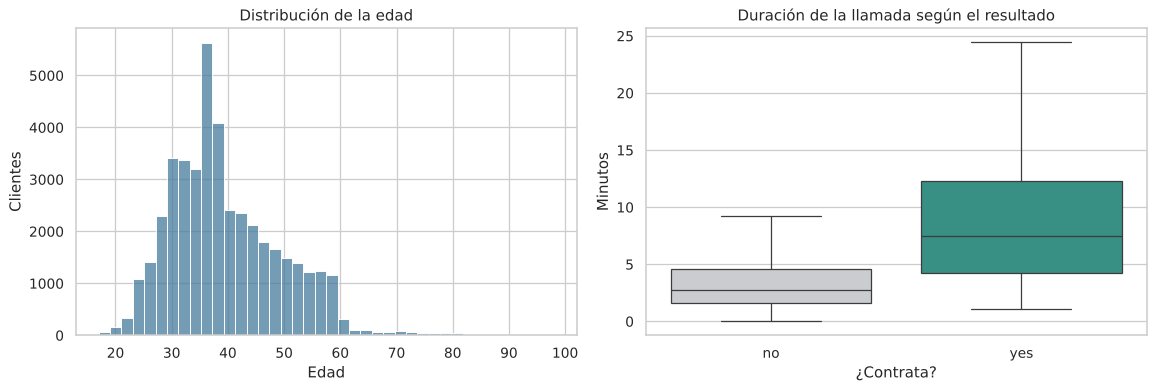

In [29]:
COLOR_SI, COLOR_NO = "#2a9d8f", "#c9ccd1"

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(datos, x="age", bins=40, color="#457b9d", ax=ejes[0])
ejes[0].set(title="Distribución de la edad", xlabel="Edad", ylabel="Clientes")
sns.boxplot(datos, x="y", y="duracion_min", order=["no", "yes"],
            palette=[COLOR_NO, COLOR_SI], showfliers=False, ax=ejes[1])
ejes[1].set(title="Duración de la llamada según el resultado", xlabel="¿Contrata?", ylabel="Minutos")
plt.tight_layout()
plt.show()

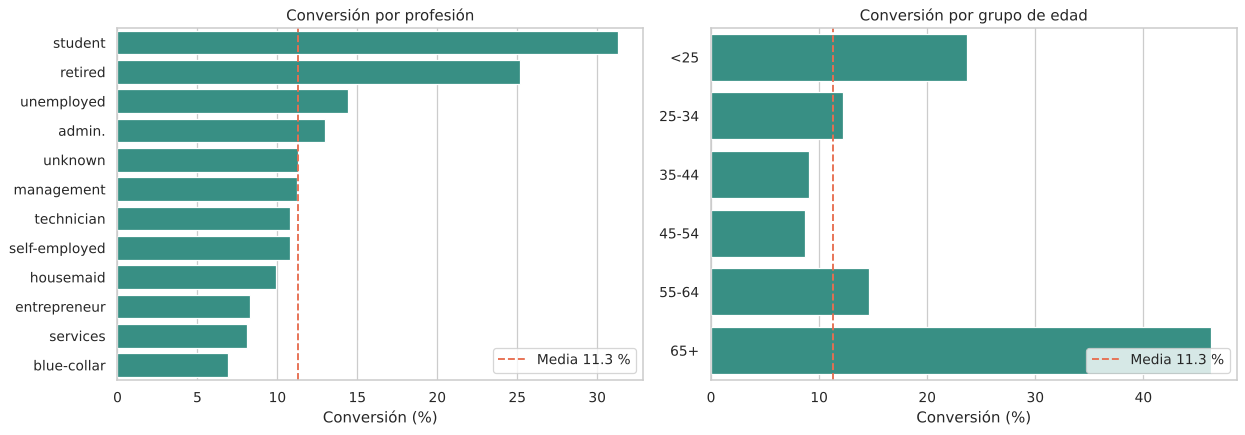

In [30]:
def barras_conversion(columna, titulo, ax, ordenar=True):
    tabla = conversion_por(columna)
    if not ordenar:
        tabla = tabla.sort_index()
    sns.barplot(x=tabla["conversion"], y=tabla.index.astype(str), color=COLOR_SI, ax=ax, orient="h")
    ax.axvline(tasa_global, color="#e76f51", linestyle="--", label=f"Media {tasa_global:.1f} %")
    ax.set(title=titulo, xlabel="Conversión (%)", ylabel="")
    ax.legend(loc="lower right")

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
barras_conversion("job", "Conversión por profesión", ejes[0])
barras_conversion("grupo_edad", "Conversión por grupo de edad", ejes[1], ordenar=False)
plt.tight_layout()
plt.show()

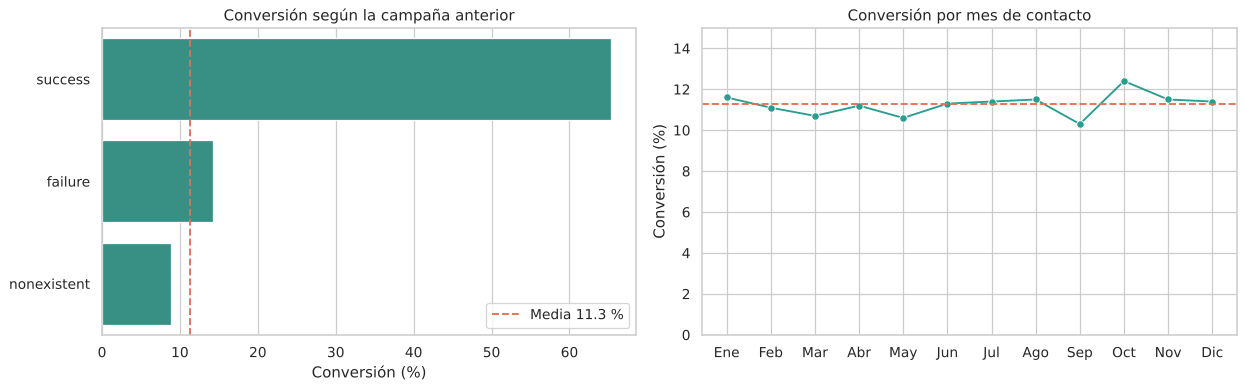

In [31]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
barras_conversion("poutcome", "Conversión según la campaña anterior", ejes[0])
mensual = conversion_por("contact_month").sort_index()
nombres_mes = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
sns.lineplot(x=[nombres_mes[m - 1] for m in mensual.index], y=mensual["conversion"],
             marker="o", color=COLOR_SI, ax=ejes[1])
ejes[1].axhline(tasa_global, color="#e76f51", linestyle="--")
ejes[1].set(title="Conversión por mes de contacto", xlabel="", ylabel="Conversión (%)", ylim=(0, 15))
plt.tight_layout()
plt.show()

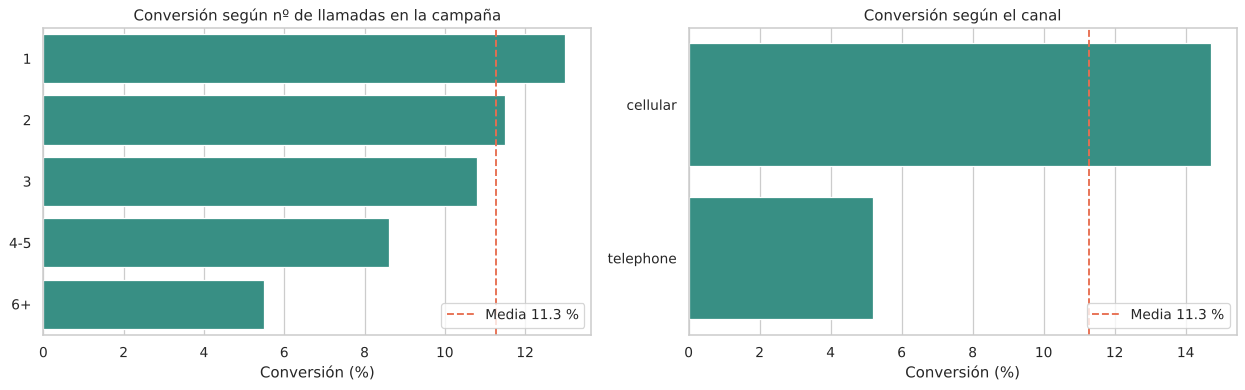

In [32]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
barras_conversion("llamadas_campania", "Conversión según nº de llamadas en la campaña", ejes[0], ordenar=False)
barras_conversion("contact", "Conversión según el canal", ejes[1])
plt.tight_layout()
plt.show()

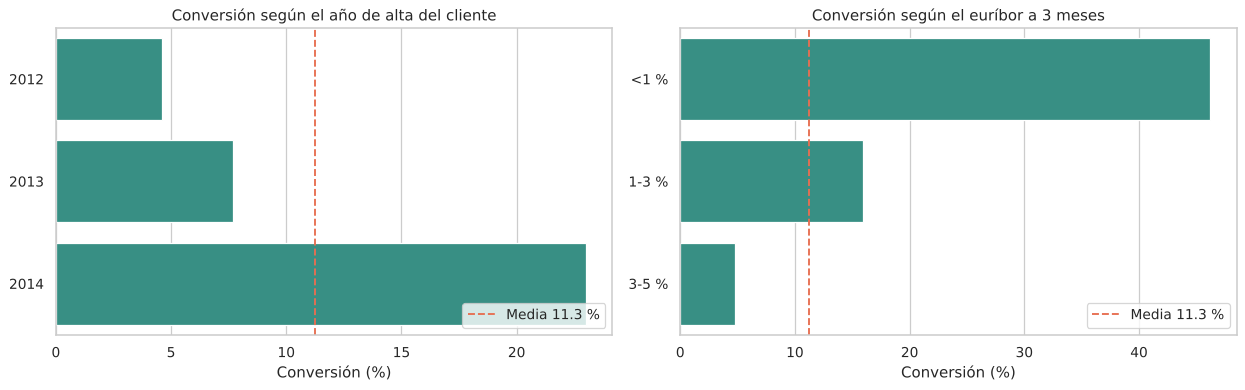

In [33]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
barras_conversion("anio_alta", "Conversión según el año de alta del cliente", ejes[0], ordenar=False)
barras_conversion("tramo_euribor", "Conversión según el euríbor a 3 meses", ejes[1], ordenar=False)
plt.tight_layout()
plt.show()

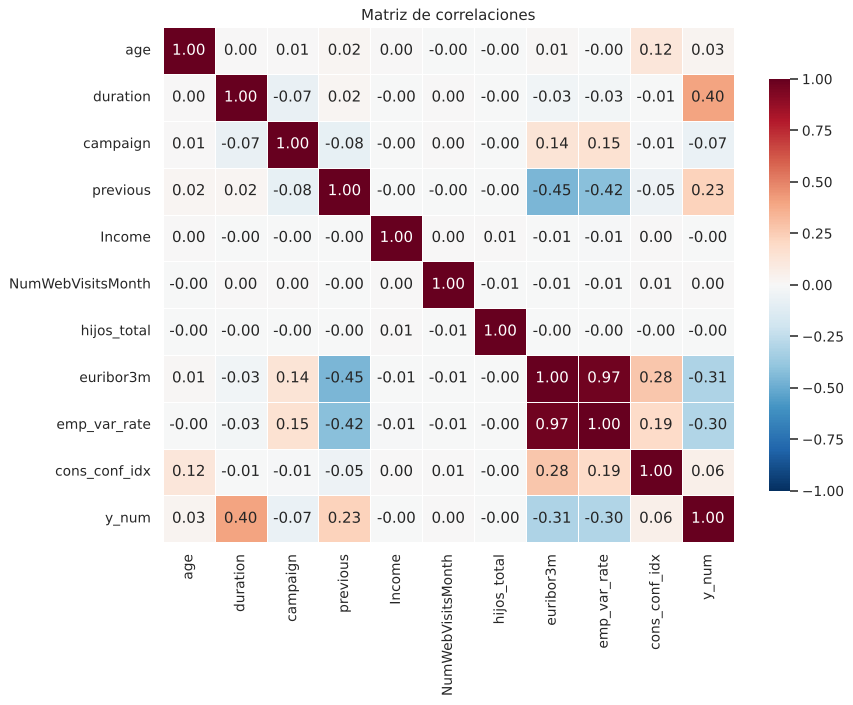

In [34]:
plt.figure(figsize=(10, 8))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Matriz de correlaciones")
plt.tight_layout()
plt.show()

## 7. Conclusiones
La campaña tuvo una **tasa de conversión del 11,3 %**: 4.844 contrataciones en 43.000 contactos. Los hallazgos principales son estos:

1. **El historial con el cliente es lo que más pesa.** Quien contrató en una campaña anterior vuelve a contratar en el **65 %** de los casos, frente al 8,8 % de quien nunca había sido contactado. Volver a llamar a los clientes que ya dijeron que sí es la acción con más retorno.
2. **La antigüedad del cliente también marca diferencias.** Los clientes dados de alta en 2014 convierten un **23 %**, frente al 7,7 % de los de 2013 y el 4,6 % de los de 2012. Los clientes recientes son mucho más receptivos.
3. **El perfil por edad y profesión tiene forma de U.** Los mayores de 65 (46 %) y los menores de 25 (24 %) son los que más contratan, igual que los **estudiantes (31 %)** y los **jubilados (25 %)**. Las franjas de 35 a 54 años y los perfiles *blue-collar* (6,9 %) y *services* (8,1 %) son los menos receptivos.
4. **El contexto económico importa.** Con el euríbor por debajo del 1 % la conversión es del **46 %**; por encima del 3 %, solo del 4,8 %. La correlación entre euríbor y conversión es de −0,31. Con tipos bajos, el depósito a plazo resulta relativamente más atractivo y es el mejor momento para lanzar campañas.
5. **El canal y la insistencia.** El móvil convierte casi el triple que el fijo (14,7 % frente a 5,2 %). La conversión cae con cada llamada adicional: 13 % con una llamada y 5,5 % a partir de seis. Insistir más de tres veces apenas compensa.
6. **La duración de la llamada es la variable más correlacionada con el éxito (0,41)**: las llamadas que acaban en contratación duran una mediana de 7,5 minutos, frente a 2,7. Sin embargo, la duración solo se conoce **después** de la llamada, así que sirve para describir lo que pasó, no para elegir a quién llamar.
7. **Lo que no marca diferencias:** los ingresos (entre el 10,8 % y el 11,5 % en todos los cuartiles), el número de hijos, tener hipoteca o préstamo, y el mes del contacto (entre el 10,3 % y el 12,4 %).

**Recomendación:** priorizar a los clientes con éxito previo, los de alta reciente y los perfiles de estudiantes y jubilados; contactar por móvil; no pasar de tres llamadas por cliente; e intensificar la campaña cuando los tipos de interés están bajos.

**Limitaciones:**
- La edad se imputó en un 12 % de los registros (con la mediana de su profesión) y el euríbor en un 21 % (con la mediana de su periodo económico).
- Las fechas de contacto (2015–2019) y los indicadores económicos no siempre son coherentes entre sí: el dataset parece haber sido modificado con fines didácticos.
- El análisis es descriptivo: muestra relaciones, no causas.
